# End-to-End Retail Data Analysis & Prediction Project
**Berkant Duman | April 2026** | Project from the MetBrains 7-day Data Camp

---
This notebook covers:
1. **Part 2 – Exploratory Data Analysis (EDA)** in Python
2. **Part 3 – Predictive analysis** with Linear Regression
3. **Key business insights**, written from the results below

Part 1 (Tableau dashboard) is linked in the repository README.


##  Import Libraries

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings('ignore')

# Global plot style
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
sns.set_palette("Set2")
print("Libraries loaded successfully.")

Libraries loaded successfully.


##  Part 2 – Exploratory Data Analysis (EDA)
### 2.1 Load Dataset

In [44]:
from google.colab import files
uploaded = files.upload()

import io
df = pd.read_csv(io.BytesIO(list(uploaded.values())[0]))
print(f"Dataset shape: {df.shape[0]} rows × {df.shape[1]} columns")
df.head()

Saving file2.csv to file2 (3).csv
Dataset shape: 1600 rows × 12 columns


,Order_Date,Country,City,Category,Sub_Category,Segment,Sales_Channel,Payment_Mode,Sales,Quantity,Discount,Profit
0,2022-06-20,UAE,Dubai,Furniture,Snacks,Consumer,Offline,UPI,2555.49,11,0.08,255.37
1,2023-12-05,UK,London,Sports,Phones,Home Office,Online,Net Banking,1795.27,9,0.28,-332.23
2,2022-07-05,USA,Los Angeles,Electronics,Shirts,Consumer,Offline,UPI,4554.73,10,0.13,140.24
3,2024-10-05,USA,New York,Furniture,Phones,Consumer,Online,Net Banking,3107.15,13,0.14,60.70
4,2023-07-21,USA,New York,Beauty,Fitness,Consumer,Offline,Card,2781.45,12,0.20,61.78


### 2.2 Dataset Structure & Data Types

In [45]:
print("=== Column Info ===")
df.info()
print("\n=== First 5 Rows ===")
df.head()

=== Column Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1600 entries, 0 to 1599
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order_Date     1600 non-null   object 
 1   Country        1600 non-null   object 
 2   City           1600 non-null   object 
 3   Category       1600 non-null   object 
 4   Sub_Category   1600 non-null   object 
 5   Segment        1600 non-null   object 
 6   Sales_Channel  1600 non-null   object 
 7   Payment_Mode   1600 non-null   object 
 8   Sales          1600 non-null   float64
 9   Quantity       1600 non-null   int64  
 10  Discount       1600 non-null   float64
 11  Profit         1600 non-null   float64
dtypes: float64(3), int64(1), object(8)
memory usage: 150.1+ KB

=== First 5 Rows ===


,Order_Date,Country,City,Category,Sub_Category,Segment,Sales_Channel,Payment_Mode,Sales,Quantity,Discount,Profit
0,2022-06-20,UAE,Dubai,Furniture,Snacks,Consumer,Offline,UPI,2555.49,11,0.08,255.37
1,2023-12-05,UK,London,Sports,Phones,Home Office,Online,Net Banking,1795.27,9,0.28,-332.23
2,2022-07-05,USA,Los Angeles,Electronics,Shirts,Consumer,Offline,UPI,4554.73,10,0.13,140.24
3,2024-10-05,USA,New York,Furniture,Phones,Consumer,Online,Net Banking,3107.15,13,0.14,60.70
4,2023-07-21,USA,New York,Beauty,Fitness,Consumer,Offline,Card,2781.45,12,0.20,61.78


### 2.3 Summary Statistics

In [46]:
df.describe().round(2)

,Sales,Quantity,Discount,Profit
count,1600.00,1600.00,1600.00,1600.00
mean,2527.24,7.58,0.15,244.33
std,1410.95,4.00,0.09,515.34
min,100.26,1.00,0.00,-937.75
25%,1293.73,4.00,0.07,-88.15
50%,2496.75,8.00,0.15,138.66
75%,3715.99,11.00,0.22,535.82
max,4996.12,14.00,0.30,1921.42


### 2.4 Missing Values & Duplicates

In [47]:
print("Missing values per column:")
print(df.isnull().sum())
print(f"\nTotal duplicate rows: {df.duplicated().sum()}")
print("\n No missing values or duplicates — dataset is clean")

Missing values per column:
Order_Date       0
Country          0
City             0
Category         0
Sub_Category     0
Segment          0
Sales_Channel    0
Payment_Mode     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Total duplicate rows: 0

 No missing values or duplicates — dataset is clean


### 2.5 Feature Engineering — Parse Dates

In [48]:
df['Order_Date'] = pd.to_datetime(df['Order_Date'])
df['Year'] = df['Order_Date'].dt.year
df['Month'] = df['Order_Date'].dt.month
df['Month_Name'] = df['Order_Date'].dt.strftime('%b')
print("Date parsing complete. Sample:")
df[['Order_Date', 'Year', 'Month', 'Month_Name']].head()

Date parsing complete. Sample:


,Order_Date,Year,Month,Month_Name
0,2022-06-20,2022,6,Jun
1,2023-12-05,2023,12,Dec
2,2022-07-05,2022,7,Jul
3,2024-10-05,2024,10,Oct
4,2023-07-21,2023,7,Jul


### 2.6 Distribution of Key Numeric Variables

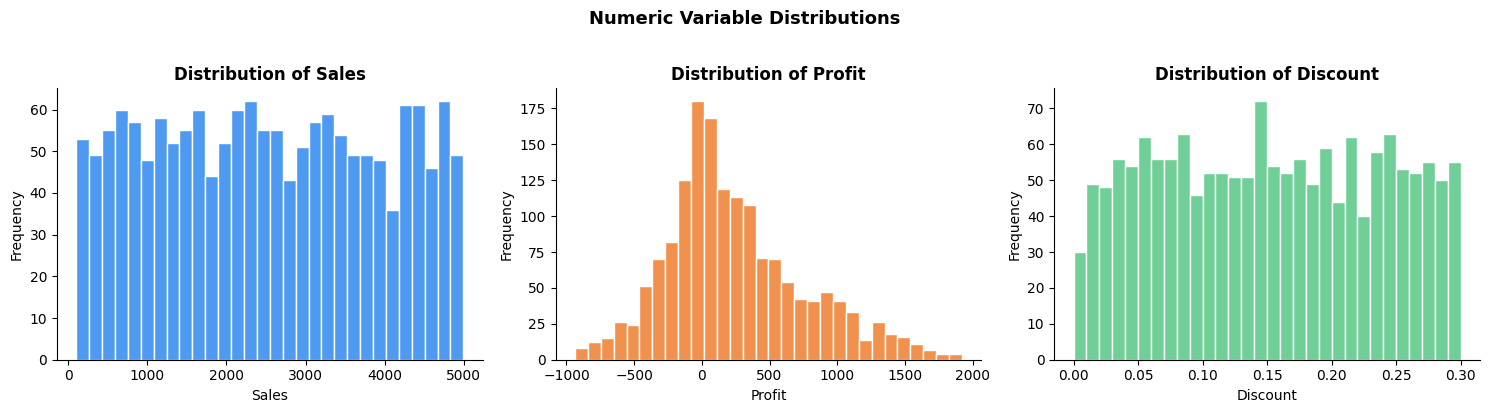

Observation: Sales is roughly uniform ($100–$5000). Profit is widely spread including losses.


In [49]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, color in zip(axes, ['Sales', 'Profit', 'Discount'],
                           ['#4e9af1', '#f1914e', '#6fcf97']):
    ax.hist(df[col], bins=30, color=color, edgecolor='white')
    ax.set_title(f'Distribution of {col}', fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')
plt.suptitle('Numeric Variable Distributions', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('fig_distributions.png', dpi=120, bbox_inches='tight')
plt.show()
print("Observation: Sales is roughly uniform ($100–$5000). Profit is widely spread including losses.")

### 2.7 Sales by Category

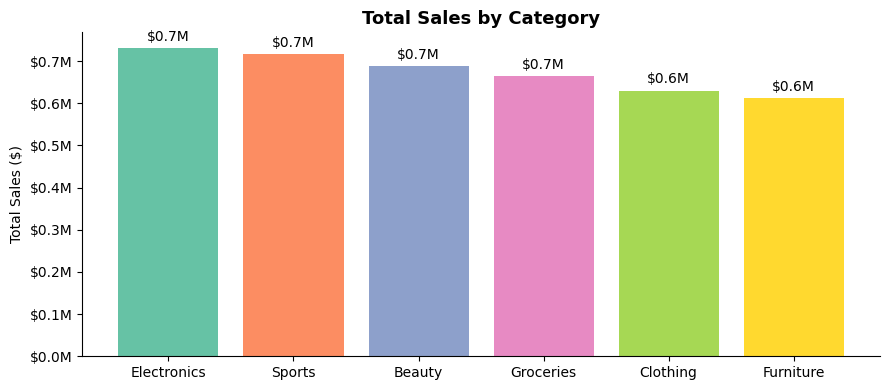

In [50]:
cat_sales = df.groupby('Category')['Sales'].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(cat_sales.index, cat_sales.values, color=sns.color_palette("Set2", len(cat_sales)))
ax.bar_label(bars, labels=[f'${v/1e6:.1f}M' for v in cat_sales.values], padding=3)
ax.set_title('Total Sales by Category', fontweight='bold', fontsize=13)
ax.set_ylabel('Total Sales ($)')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
plt.tight_layout()
plt.savefig('fig_category_sales.png', dpi=120, bbox_inches='tight')
plt.show()

### 2.8 Sales & Profit by Country (Region)

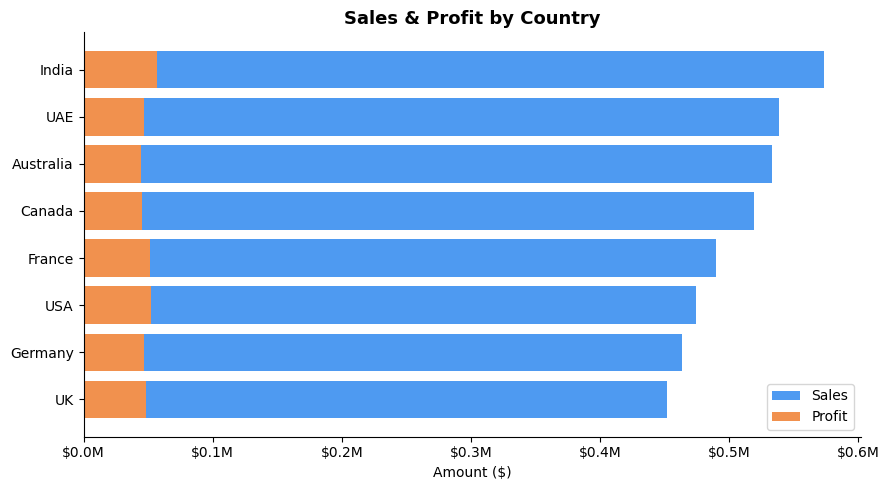

In [51]:
region = df.groupby('Country')[['Sales', 'Profit']].sum().sort_values('Sales', ascending=True)
fig, ax = plt.subplots(figsize=(9, 5))
x = range(len(region))
ax.barh(region.index, region['Sales'], color='#4e9af1', label='Sales')
ax.barh(region.index, region['Profit'], color='#f1914e', label='Profit')
ax.set_title('Sales & Profit by Country', fontweight='bold', fontsize=13)
ax.set_xlabel('Amount ($)')
ax.legend()
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
plt.tight_layout()
plt.savefig('fig_region.png', dpi=120, bbox_inches='tight')
plt.show()

### 2.9 Sales by Customer Segment

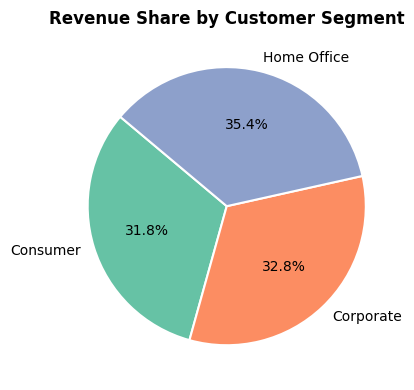

In [52]:
seg = df.groupby('Segment')['Sales'].sum()
fig, ax = plt.subplots(figsize=(6, 4))
ax.pie(seg.values, labels=seg.index, autopct='%1.1f%%',
       colors=sns.color_palette("Set2", len(seg)), startangle=140,
       wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
ax.set_title('Revenue Share by Customer Segment', fontweight='bold')
plt.tight_layout()
plt.savefig('fig_segment.png', dpi=120, bbox_inches='tight')
plt.show()

### 2.10 Monthly Sales Trend by Year

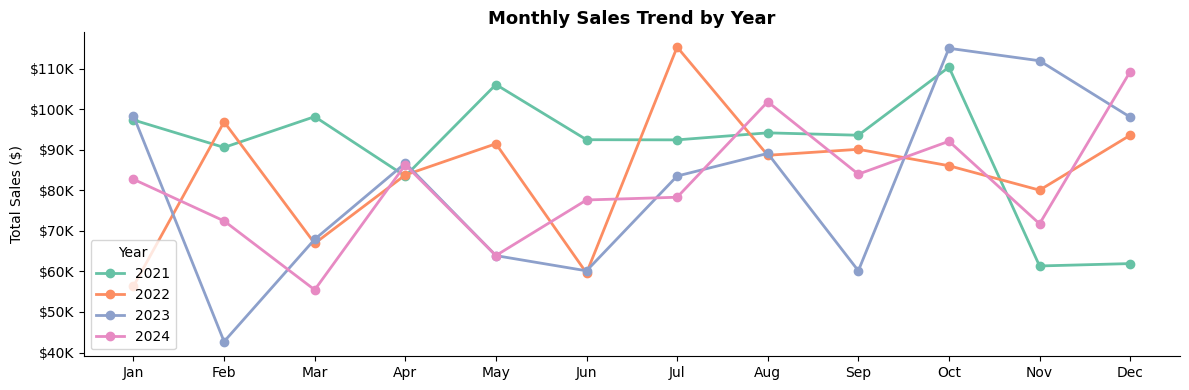

In [53]:
monthly = df.groupby(['Year', 'Month'])['Sales'].sum().reset_index()
fig, ax = plt.subplots(figsize=(12, 4))
for year, grp in monthly.groupby('Year'):
    ax.plot(grp['Month'], grp['Sales'], marker='o', label=str(year), linewidth=2)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
ax.set_title('Monthly Sales Trend by Year', fontweight='bold', fontsize=13)
ax.set_ylabel('Total Sales ($)')
ax.legend(title='Year')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x/1e3:.0f}K'))
plt.tight_layout()
plt.savefig('fig_monthly_trend.png', dpi=120, bbox_inches='tight')
plt.show()

### 2.11 Discount vs Profit Relationship

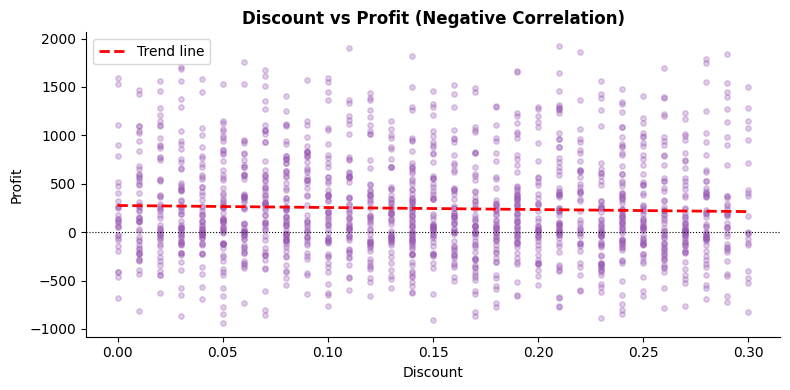

Pearson correlation (Discount vs Profit): -0.035


In [54]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(df['Discount'], df['Profit'], alpha=0.3, color='#9b59b6', s=15)
z = np.polyfit(df['Discount'], df['Profit'], 1)
p = np.poly1d(z)
x_line = np.linspace(df['Discount'].min(), df['Discount'].max(), 200)
ax.plot(x_line, p(x_line), 'r--', linewidth=2, label='Trend line')
ax.axhline(0, color='black', linewidth=0.8, linestyle=':')
ax.set_xlabel('Discount')
ax.set_ylabel('Profit')
ax.set_title('Discount vs Profit (Negative Correlation)', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('fig_discount_profit.png', dpi=120, bbox_inches='tight')
plt.show()
corr = df['Discount'].corr(df['Profit'])
print(f"Pearson correlation (Discount vs Profit): {corr:.3f}")

### 2.12 Correlation Heatmap

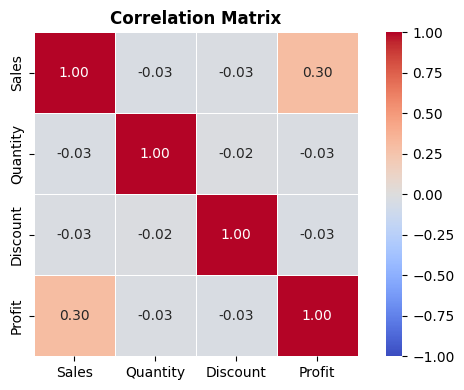

In [55]:
fig, ax = plt.subplots(figsize=(6, 4))
corr_matrix = df[['Sales', 'Quantity', 'Discount', 'Profit']].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            square=True, linewidths=0.5, ax=ax, vmin=-1, vmax=1)
ax.set_title('Correlation Matrix', fontweight='bold')
plt.tight_layout()
plt.savefig('fig_heatmap.png', dpi=120, bbox_inches='tight')
plt.show()

### 2.13 Sales by Payment Mode & Sales Channel

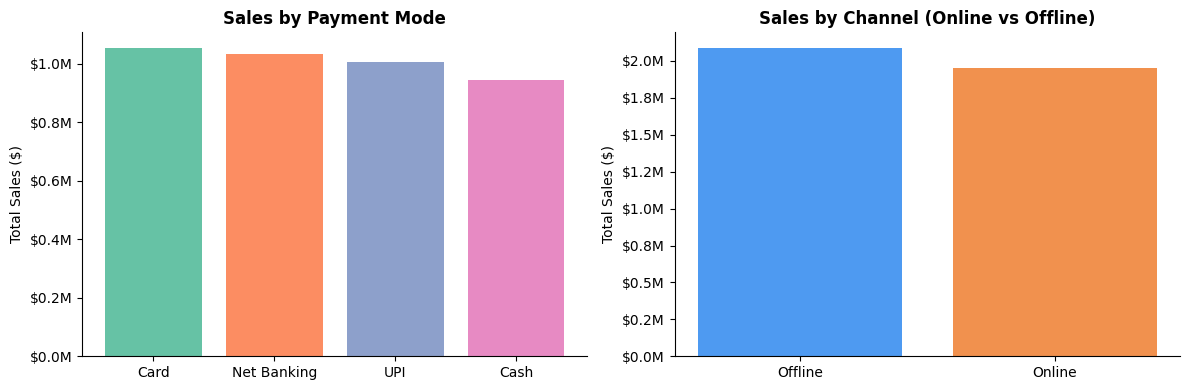

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pay = df.groupby('Payment_Mode')['Sales'].sum().sort_values(ascending=False)
axes[0].bar(pay.index, pay.values, color=sns.color_palette("Set2", len(pay)))
axes[0].set_title('Sales by Payment Mode', fontweight='bold')
axes[0].set_ylabel('Total Sales ($)')
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))

chan = df.groupby('Sales_Channel')['Sales'].sum()
axes[1].bar(chan.index, chan.values, color=['#4e9af1', '#f1914e'])
axes[1].set_title('Sales by Channel (Online vs Offline)', fontweight='bold')
axes[1].set_ylabel('Total Sales ($)')
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
plt.tight_layout()
plt.savefig('fig_payment_channel.png', dpi=120, bbox_inches='tight')
plt.show()

---
##  Part 3 – Predictive Analysis (Machine Learning)
### 3.1 Problem Statement
**Goal:** Predict **Sales** based on available features (Quantity, Discount, Category, Segment, Country, etc.) using **Linear Regression**.


### 3.2 Feature Engineering & Encoding

In [57]:
df_ml = df.copy()

# Encode categorical features
le = LabelEncoder()
cat_cols = ['Category', 'Sub_Category', 'Segment', 'Country', 'Sales_Channel', 'Payment_Mode']
for col in cat_cols:
    df_ml[col + '_enc'] = le.fit_transform(df_ml[col])

# Features and Target
feature_cols = ['Quantity', 'Discount', 'Month', 'Year',
                'Category_enc', 'Sub_Category_enc', 'Segment_enc',
                'Country_enc', 'Sales_Channel_enc', 'Payment_Mode_enc']

X = df_ml[feature_cols]
y = df_ml['Sales']

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
X.head()

Feature matrix shape: (1600, 10)
Target shape: (1600,)


,Quantity,Discount,Month,Year,Category_enc,Sub_Category_enc,Segment_enc,Country_enc,Sales_Channel_enc,Payment_Mode_enc
0,11,0.08,6,2022,3,5,0,5,0,3
1,9,0.28,12,2023,5,3,2,6,1,2
2,10,0.13,7,2022,2,4,0,7,0,3
3,13,0.14,10,2024,3,3,0,7,1,2
4,12,0.20,7,2023,0,2,0,7,0,0


### 3.3 Train-Test Split

In [58]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print(f"Training samples : {X_train.shape[0]}")
print(f"Testing samples  : {X_test.shape[0]}")

Training samples : 1280
Testing samples  : 320


### 3.4 Train Linear Regression Model

In [59]:
model = LinearRegression()
model.fit(X_train, y_train)
print(" Model trained successfully.")
print("\nModel Coefficients:")
coef_df = pd.DataFrame({'Feature': feature_cols, 'Coefficient': model.coef_}).sort_values('Coefficient', ascending=False)
print(coef_df.to_string(index=False))

 Model trained successfully.

Model Coefficients:
          Feature  Coefficient
      Segment_enc    60.007110
 Payment_Mode_enc    49.609236
             Year    26.898073
 Sub_Category_enc    19.482534
     Category_enc    17.010223
Sales_Channel_enc    14.218559
      Country_enc     4.403245
         Quantity    -6.267522
            Month   -15.016644
         Discount  -557.101389


### 3.5 Model Evaluation

In [60]:
y_pred = model.predict(X_test)

mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2   = r2_score(y_test, y_pred)

print("=" * 35)
print(f"  Mean Absolute Error  : ${mae:,.2f}")
print(f"  RMSE                 : ${rmse:,.2f}")
print(f"  R² Score             : {r2:.4f}")
print("=" * 35)

  Mean Absolute Error  : $1,300.21
  RMSE                 : $1,502.35
  R² Score             : -0.0109


### 3.6 Actual vs Predicted Sales Plot

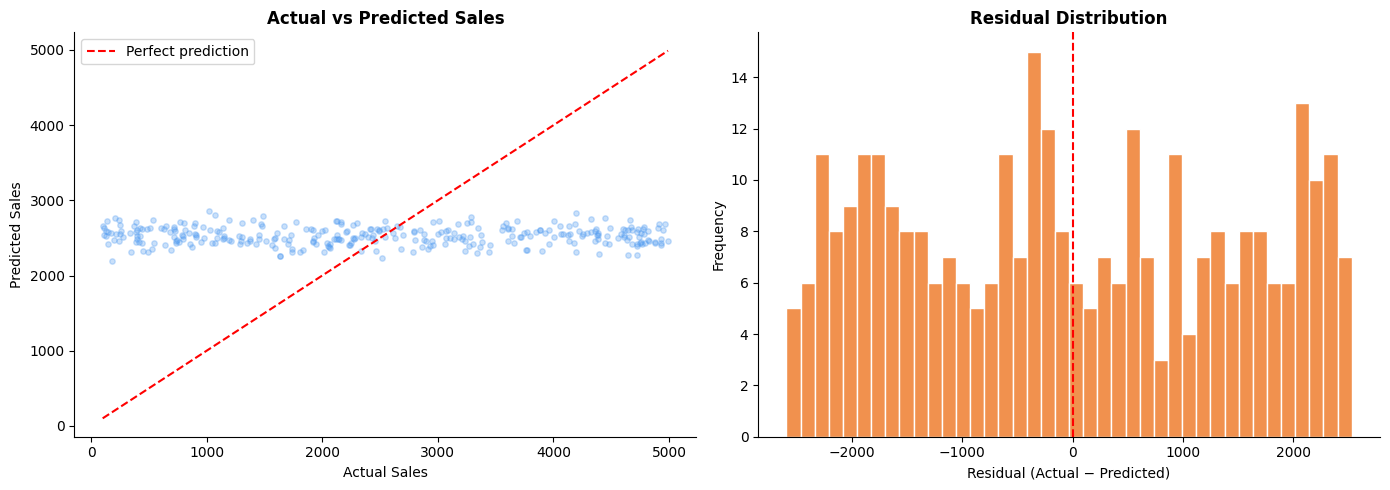

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter
axes[0].scatter(y_test, y_pred, alpha=0.3, color='#4e9af1', s=15)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, 'r--', linewidth=1.5, label='Perfect prediction')
axes[0].set_xlabel('Actual Sales')
axes[0].set_ylabel('Predicted Sales')
axes[0].set_title('Actual vs Predicted Sales', fontweight='bold')
axes[0].legend()

# Residuals
residuals = y_test.values - y_pred
axes[1].hist(residuals, bins=40, color='#f1914e', edgecolor='white')
axes[1].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_xlabel('Residual (Actual − Predicted)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Residual Distribution', fontweight='bold')

plt.tight_layout()
plt.savefig('fig_model_eval.png', dpi=120, bbox_inches='tight')
plt.show()

### 3.7 Feature Importance (Coefficient Magnitude)

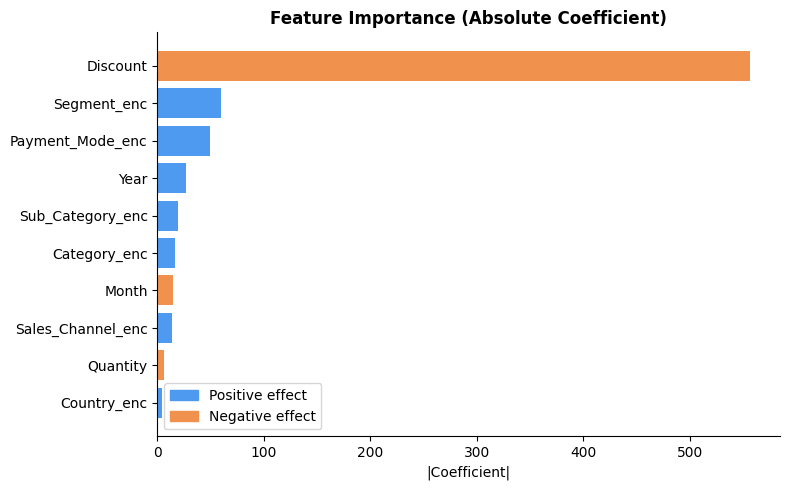

In [62]:
coef_abs = coef_df.copy()
coef_abs['Abs_Coeff'] = coef_abs['Coefficient'].abs()
coef_abs = coef_abs.sort_values('Abs_Coeff', ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#f1914e' if c < 0 else '#4e9af1' for c in coef_abs['Coefficient']]
ax.barh(coef_abs['Feature'], coef_abs['Abs_Coeff'], color=colors)
ax.set_title('Feature Importance (Absolute Coefficient)', fontweight='bold')
ax.set_xlabel('|Coefficient|')
# Legend
import matplotlib.patches as mpatches
pos_patch = mpatches.Patch(color='#4e9af1', label='Positive effect')
neg_patch = mpatches.Patch(color='#f1914e', label='Negative effect')
ax.legend(handles=[pos_patch, neg_patch])
plt.tight_layout()
plt.savefig('fig_feature_importance.png', dpi=120, bbox_inches='tight')
plt.show()

---
## Key Business Insights (from the results above)

### 1. Category performance
- **Electronics** has the highest total sales, followed closely by Sports and Beauty.
- **Furniture** and **Clothing** have the lowest totals. All six categories lie between about $0.6M and $0.7M, so no category clearly dominates.

### 2. Regional performance
- **India** has the highest sales, followed by the UAE and Australia.
- The **UK** has the lowest sales, followed by Germany and the USA.
- Profit is similar in every country, so differences between markets are small.

### 3. Customer segments
- Revenue is split almost evenly: **Home Office 35.4%**, Corporate 32.8%, Consumer 31.8%.
- No single segment carries the business, which makes revenue less dependent on one customer group.

### 4. Discount and profit
- The correlation between Discount and Profit is only **r = −0.03**, so discounts barely affect profit in this dataset.
- The only notable relationship is **Sales–Profit (r = 0.30)**: larger orders tend to bring somewhat more profit.

### 5. Payment and channel
- **Card** and **Net Banking** bring the most sales, then UPI and Cash, but the differences are small.
- **Offline** sales are slightly higher than online sales.

### 6. Monthly trends
- Monthly sales jump up and down from year to year without a repeating seasonal pattern.

### 7. Machine learning model
- Linear Regression gives **R² = −0.01**, MAE ≈ $1,300 and RMSE ≈ $1,502. The model predicts almost the same value (about $2,500) for every order, so it does no better than using the average.
- Together with the near-zero correlations and the evenly spread distributions, this suggests the dataset is close to **randomly generated**: there is no strong signal for any model to learn.
- **Lesson:** checking whether the data contains real patterns comes before choosing a more complex model. With real company data, the next steps would be one-hot encoding instead of label encoding, and testing tree-based models such as Random Forest.

### Business recommendations
- Treat the categories, markets and segments as roughly equal; no area needs urgent rescue.
- Investigate India and the UAE as growth markets and the UK as the weakest market.
- Collect richer data (customer history, prices, promotions) before relying on sales predictions.


---
*Berkant Duman, April 2026 | Project brief: MetBrains 7-day Data Camp*
